In [1]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df = pd.read_csv("../Dataset/clinical_data.csv")

In [7]:
df.head(10)

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,PAT_684_1302_588.png,True
5,PAT_1549,1882,NaN,NaN,NaN,NaN,53,NaN,NaN,NaN,...,NaN,SEK,TRUE,FALSE,FALSE,FALSE,FALSE,TRUE,PAT_1549_1882_230.png,False
6,PAT_778,1471,False,True,GERMANY,ITALY,52,False,FEMALE,False,...,10.0,BCC,FALSE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_778_1471_835.png,True
7,PAT_117,179,False,False,POMERANIA,POMERANIA,74,True,FEMALE,False,...,10.0,BCC,TRUE,TRUE,TRUE,FALSE,TRUE,TRUE,PAT_117_179_983.png,True
8,PAT_1995,4080,NaN,NaN,NaN,NaN,68,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,TRUE,FALSE,FALSE,PAT_1995_4080_695.png,False
9,PAT_705,4015,False,True,GERMANY,GERMANY,58,True,FEMALE,True,...,7.0,ACK,FALSE,TRUE,FALSE,FALSE,FALSE,FALSE,PAT_705_4015_413.png,False


In [8]:
df.describe()

,lesion_id,age,fitspatrick,diameter_1,diameter_2
count,2298.000000,2298.000000,1494.000000,1494.000000,1494.000000
mean,1529.933856,60.464752,2.265730,11.897055,8.852209
std,1196.285644,15.894866,0.729029,8.634492,5.797036
min,6.000000,6.000000,1.000000,0.000000,0.000000
25%,720.500000,52.000000,2.000000,7.000000,5.000000
50%,1297.000000,62.000000,2.000000,10.000000,8.000000
75%,1782.750000,72.000000,3.000000,15.000000,10.000000
max,4820.000000,94.000000,6.000000,100.000000,70.000000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           2298 non-null   object 
 1   lesion_id            2298 non-null   int64  
 2   smoke                1494 non-null   object 
 3   drink                1494 non-null   object 
 4   background_father    1480 non-null   object 
 5   background_mother    1476 non-null   object 
 6   age                  2298 non-null   int64  
 7   pesticide            1494 non-null   object 
 8   gender               1494 non-null   object 
 9   skin_cancer_history  1494 non-null   object 
 10  cancer_history       1494 non-null   object 
 11  has_piped_water      1494 non-null   object 
 12  has_sewage_system    1494 non-null   object 
 13  fitspatrick          1494 non-null   float64
 14  region               2298 non-null   object 
 15  diameter_1           1494 non-null   f

In [10]:
print("Shape:",df.shape)

Shape: (2298, 26)


In [12]:
#unique values in each column
pd.DataFrame({
    "dtype": df.dtypes,
    "n_unique": df.nunique(),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1),
}).sort_values("pct_missing", ascending=False)

,dtype,n_unique,n_missing,pct_missing
background_mother,object,11,822,35.8
background_father,object,13,818,35.6
pesticide,object,2,804,35.0
gender,object,2,804,35.0
drink,object,2,804,35.0
smoke,object,2,804,35.0
skin_cancer_history,object,2,804,35.0
has_sewage_system,object,2,804,35.0
has_piped_water,object,2,804,35.0
cancer_history,object,2,804,35.0


In [6]:
#Standardize values

df = df.replace({"UNK": np.nan, "unk":np.nan, "": np.nan})

bool_cols = ["smoke","drink","pesticide","skin_cancer_history","cancer_history","has_piped_water",
             "has_sewage_system","itch","grew","hurt","changed","bleed","elevation","biopsed"]

for c in bool_cols:
    df[c] = (df[c].astype(str).str.upper().map({"TRUE": 1, "FALSE": 0, "1": 1, "0": 0, "1.0" : 1, "0.0" : 0}))

#Name and  numeric type

df= df.rename (columns={"fitspatrick": "fitzpatrick"})    
for c in ["age", "fitzpatrick","diameter_1","diameter_2"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

#Target grouping
malignant = ["BCC", "SCC", "MEL"]
df["is_cancer"] = df["diagnostic"].isin(malignant).astype(int)
df["diag_group"] = np.where(df["is_cancer"] == 1, "Malignant", "Benign")

cat_cols = ["gender", "region", "background_father", "background_mother"]
num_cols = ["age", "diameter_1", "diameter_2", "fitzpatrick"]
df.dtypes


patient_id              object
lesion_id                int64
smoke                  float64
drink                  float64
background_father       object
background_mother       object
age                      int64
pesticide              float64
gender                  object
skin_cancer_history    float64
cancer_history         float64
has_piped_water        float64
has_sewage_system      float64
fitzpatrick            float64
region                  object
diameter_1             float64
diameter_2             float64
diagnostic              object
itch                   float64
grew                   float64
hurt                   float64
changed                float64
bleed                  float64
elevation              float64
img_id                  object
biopsed                  int64
is_cancer                int64
diag_group              object
dtype: object

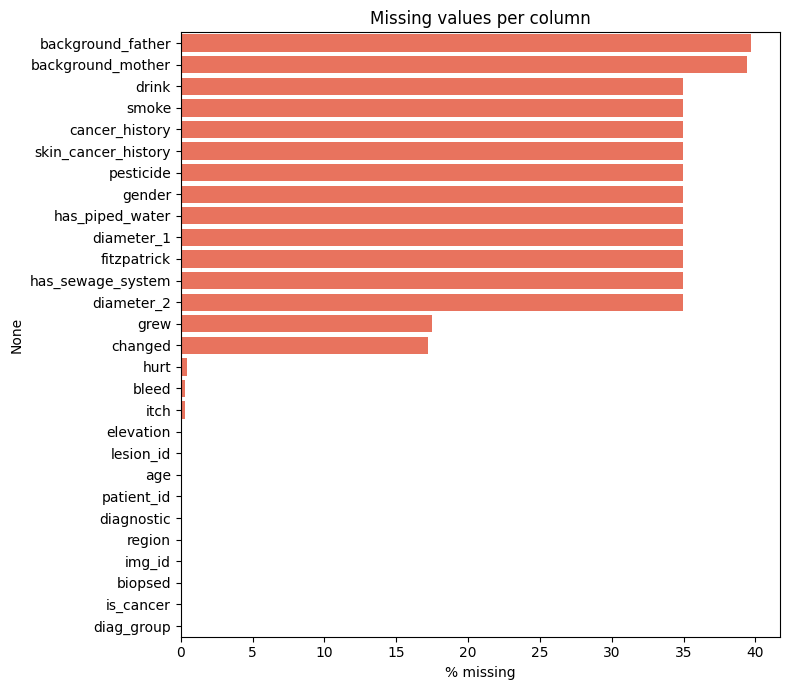

In [13]:
#missing values 
miss = (df.isna().mean() * 100).sort_values(ascending=False)
plt.figure(figsize=(8, 7))
sns.barplot(x=miss.values, y=miss.index, color="tomato")
plt.xlabel("% missing"); plt.title("Missing values per column")
plt.tight_layout(); plt.show()

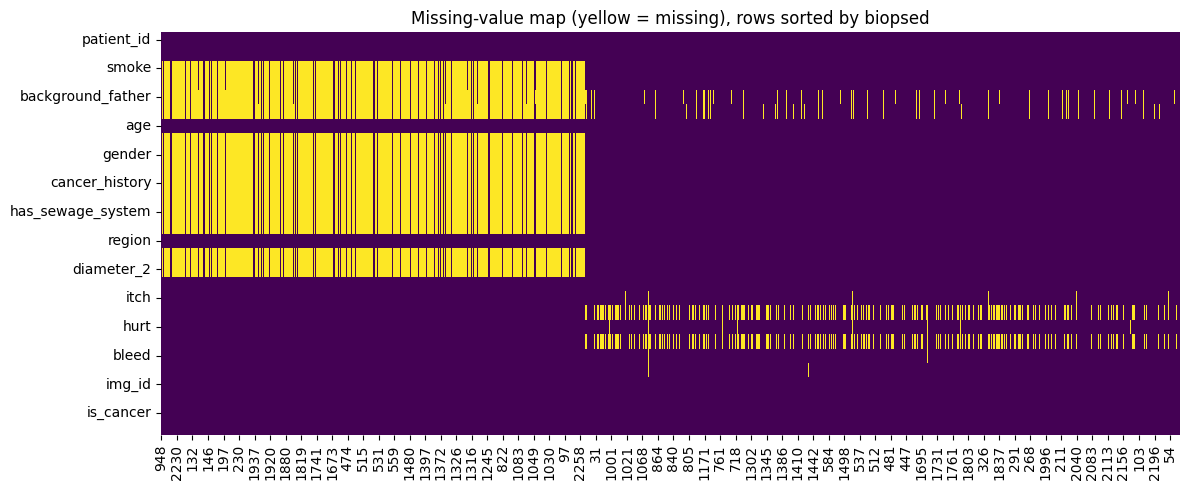

In [14]:
# Missingness heatmap 
plt.figure(figsize=(12, 5))
sns.heatmap(df.sort_values("biopsed").isna().T, cbar=False, cmap="viridis")
plt.title("Missing-value map (yellow = missing), rows sorted by biopsed")
plt.tight_layout(); plt.show()

In [15]:
# Missingness  clinical-survey fields only collected for biopsied lesions
clinical_cols = ["smoke", "drink", "background_father", "background_mother", "pesticide",
                 "gender", "skin_cancer_history", "cancer_history", "has_piped_water",
                 "has_sewage_system", "fitzpatrick", "diameter_1", "diameter_2"]
df["n_clinical_missing"] = df[clinical_cols].isna().sum(axis=1)
print(pd.crosstab(df["biopsed"], df["n_clinical_missing"] >= 8,
                  rownames=["biopsed"], colnames=["≥8 clinical fields missing"]))
print("\nMissing % of clinical fields by diagnosis:")
print((df.groupby("diagnostic")[clinical_cols].apply(lambda g: g.isna().mean()) * 100).round(0))

≥8 clinical fields missing  False  True 
biopsed                                 
0                             152    804
1                            1342      0

Missing % of clinical fields by diagnosis:
            smoke  drink  background_father  background_mother  pesticide  \
diagnostic                                                                  
ACK          61.0   61.0               65.0               64.0       61.0   
BCC           0.0    0.0                5.0                5.0        0.0   
MEL           0.0    0.0               10.0               10.0        0.0   
NEV          69.0   69.0               75.0               75.0       69.0   
SCC           0.0    0.0                7.0                6.0        0.0   
SEK          80.0   80.0               85.0               85.0       80.0   

            gender  skin_cancer_history  cancer_history  has_piped_water  \
diagnostic                                                                 
ACK           61.0     

In [17]:
#Duplictae and identifier

print("Duplicate img_id:", df["img_id"].duplicated().sum())
print("Unique patients:", df["patient_id"].nunique(), "| unique lesions:",
      df.groupby(["patient_id", "lesion_id"]).ngroups, "| rows:", len(df))

# Same  photographed several times 
imgs_per_lesion = df.groupby(["patient_id", "lesion_id"]).size()
print("\nImages per lesion:\n", imgs_per_lesion.value_counts().sort_index())

# Lesions per patient
print("\nLesions per patient:\n",
      df.groupby("patient_id")["lesion_id"].nunique().value_counts().sort_index())

# Rows identical except for img_id (
dup_mask = df.drop(columns=["img_id"]).duplicated(keep=False)
print("\nRows identical except img_id:", dup_mask.sum())

# he same lesion_id belong to more than one patient
print("lesion_ids shared by multiple patients:",
      (df.groupby("lesion_id")["patient_id"].nunique() > 1).sum())

Duplicate img_id: 0
Unique patients: 1373 | unique lesions: 1891 | rows: 2298

Images per lesion:
 1    1530
2     324
3      31
4       4
5       1
6       1
Name: count, dtype: int64

Lesions per patient:
 lesion_id
1    1018
2     242
3      79
4      25
5       5
6       2
7       1
8       1
Name: count, dtype: int64

Rows identical except img_id: 768
lesion_ids shared by multiple patients: 250


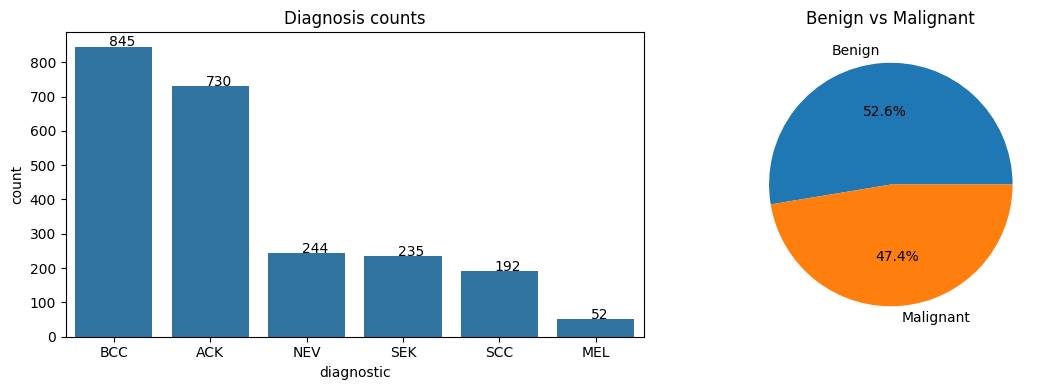

diagnostic
BCC    36.8
ACK    31.8
NEV    10.6
SEK    10.2
SCC     8.4
MEL     2.3
Name: proportion, dtype: float64

Imbalance ratio (max/min class): 16.2


In [18]:
#Target distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
order = df["diagnostic"].value_counts().index
sns.countplot(data=df, x="diagnostic", order=order, ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + .35, p.get_height() + 1))
ax[0].set_title("Diagnosis counts")
df["diag_group"].value_counts().plot.pie(autopct="%1.1f%%", ax=ax[1], ylabel="")
ax[1].set_title("Benign vs Malignant")
plt.tight_layout(); plt.show()

print((df["diagnostic"].value_counts(normalize=True) * 100).round(1))
print("\nImbalance ratio (max/min class):",
      round(df["diagnostic"].value_counts().max() / df["diagnostic"].value_counts().min(), 1))

              count       mean        std  min   25%   50%   75%    max
age          2298.0  60.464752  15.894866  6.0  52.0  62.0  72.0   94.0
diameter_1   1494.0  11.897055   8.634492  0.0   7.0  10.0  15.0  100.0
diameter_2   1494.0   8.852209   5.797036  0.0   5.0   8.0  10.0   70.0
fitzpatrick  1494.0   2.265730   0.729029  1.0   2.0   2.0   3.0    6.0

Skewness:
 age           -0.62
diameter_1     4.15
diameter_2     3.32
fitzpatrick    0.71
dtype: float64


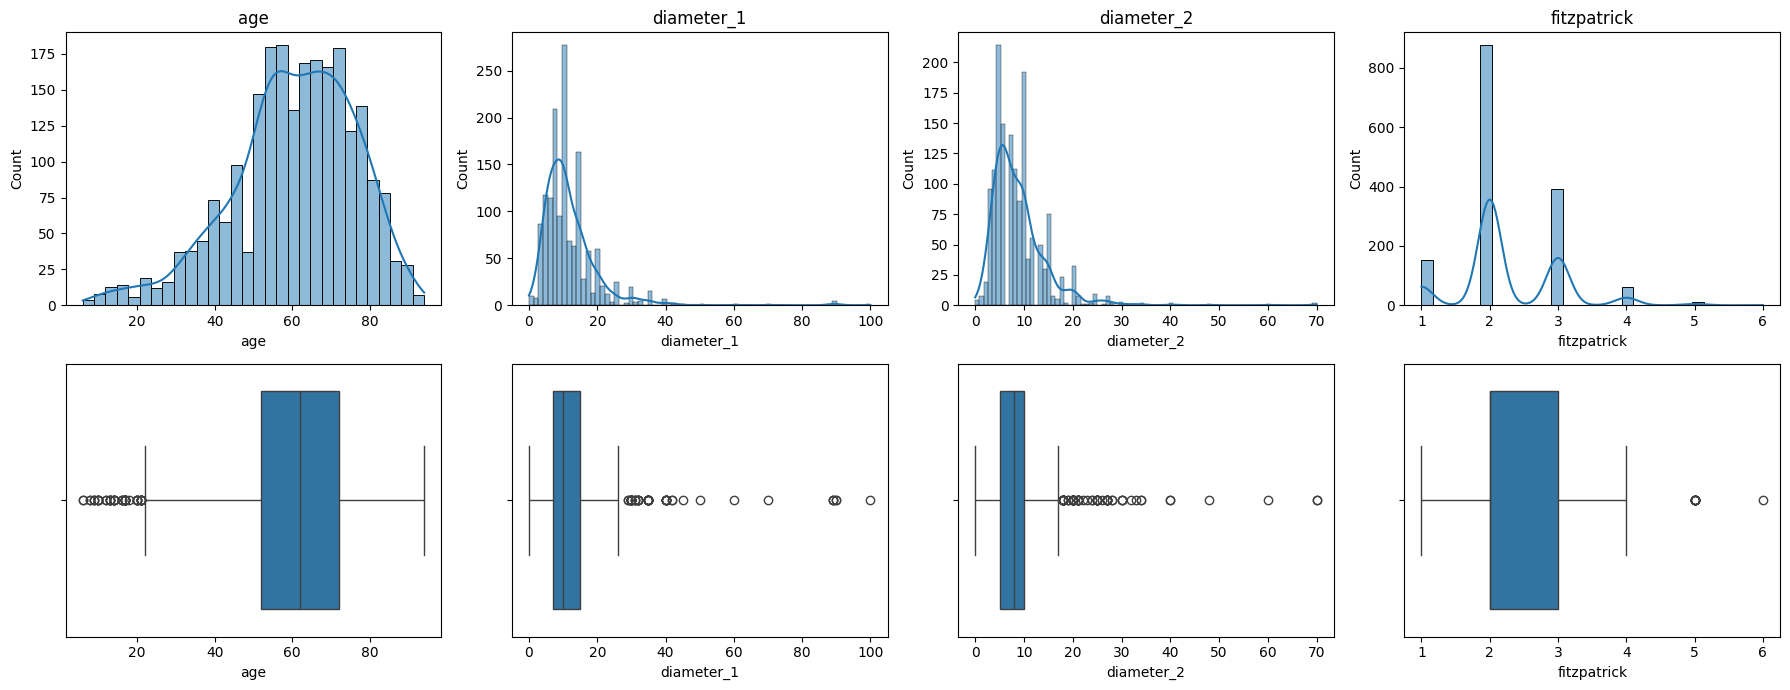

age         IQR bounds [22.0, 102.0] -> 53 outliers, max=94, min=6
diameter_1  IQR bounds [-5.0, 27.0] -> 63 outliers, max=100.0, min=0.0
diameter_2  IQR bounds [-2.5, 17.5] -> 102 outliers, max=70.0, min=0.0

diameter_2 > diameter_1: 17
age < 0 or > 100: 0


In [ ]:
#Univariate analysis for numeric features
print(df[num_cols].describe().T)
print("\nSkewness:\n", df[num_cols].skew().round(2))

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c].dropna(), kde=True, ax=axes[0, i])
    sns.boxplot(x=df[c], ax=axes[1, i])
    axes[0, i].set_title(c)
plt.tight_layout(); plt.show()

# Outliers via IQR + z-score
for c in ["age", "diameter_1", "diameter_2"]:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    print(f"{c:11s} IQR bounds [{lo:.1f}, {hi:.1f}] -> {((s < lo) | (s > hi)).sum()} outliers, "
          f"max={s.max()}, min={s.min()}")

# Logical consistency: diameter_1 should be >= diameter_2, age sane
print("\ndiameter_2 > diameter_1:", (df["diameter_2"] > df["diameter_1"]).sum())
print("age < 0 or > 100:", ((df["age"] < 0) | (df["age"] > 100)).sum())